In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [3]:
house_price_prediction = pd.read_csv("house_price_regression.csv")

In [4]:
house_price_prediction

,sqft,bedrooms,bathrooms,house_age_years,distance_to_city_km,garage_spaces,location_type,price
0,1952,3,2,32,6.5,0,Urban,325500
1,1280,1,1,58,13.0,2,Suburban,173300
2,2175,3,3,4,18.4,2,Suburban,368400
3,2270,4,3,49,13.6,0,Rural,292100
4,824,1,1,32,16.1,2,Urban,149000
...,...,...,...,...,...,...,...,...
995,1976,3,2,51,30.4,0,Suburban,264500
996,2183,3,2,13,2.4,0,Urban,364100
997,1861,3,3,18,22.6,1,Urban,292600
998,1865,2,2,10,23.5,1,Urban,271600


In [5]:
house_price_prediction.isna().sum()

sqft                   0
bedrooms               0
bathrooms              0
house_age_years        0
distance_to_city_km    0
garage_spaces          0
location_type          0
price                  0
dtype: int64

In [6]:
house_price_prediction = pd.get_dummies(house_price_prediction, columns=["location_type"], drop_first=True)

In [7]:
house_price_prediction

,sqft,bedrooms,bathrooms,house_age_years,distance_to_city_km,garage_spaces,price,location_type_Suburban,location_type_Urban
0,1952,3,2,32,6.5,0,325500,False,True
1,1280,1,1,58,13.0,2,173300,True,False
2,2175,3,3,4,18.4,2,368400,True,False
3,2270,4,3,49,13.6,0,292100,False,False
4,824,1,1,32,16.1,2,149000,False,True
...,...,...,...,...,...,...,...,...,...
995,1976,3,2,51,30.4,0,264500,True,False
996,2183,3,2,13,2.4,0,364100,False,True
997,1861,3,3,18,22.6,1,292600,False,True
998,1865,2,2,10,23.5,1,271600,False,True


In [8]:
print(house_price_prediction.columns)

Index(['sqft', 'bedrooms', 'bathrooms', 'house_age_years',
       'distance_to_city_km', 'garage_spaces', 'price',
       'location_type_Suburban', 'location_type_Urban'],
      dtype='object')


## Check the linearity test

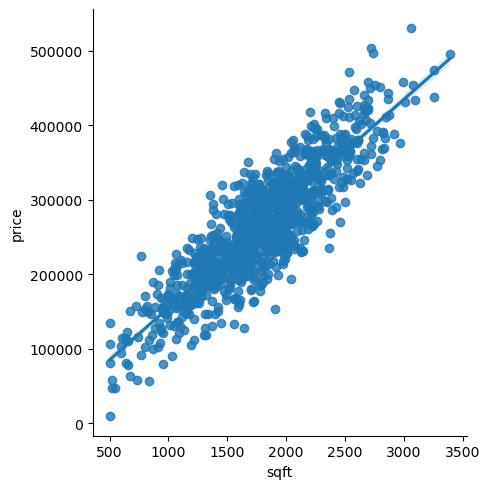

In [9]:
sns.lmplot(data=house_price_prediction, x="sqft", y='price')
plt.show()

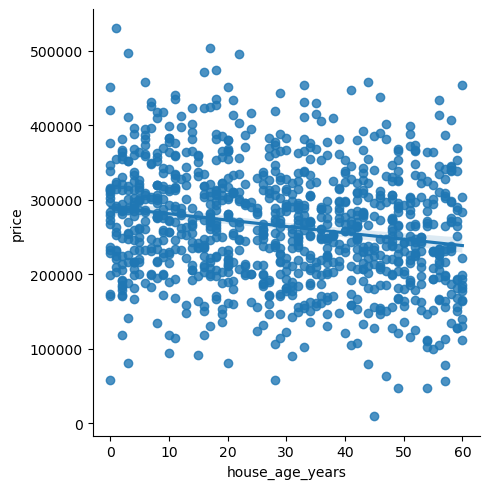

In [10]:
sns.lmplot(data=house_price_prediction, x="house_age_years", y='price')
plt.show()

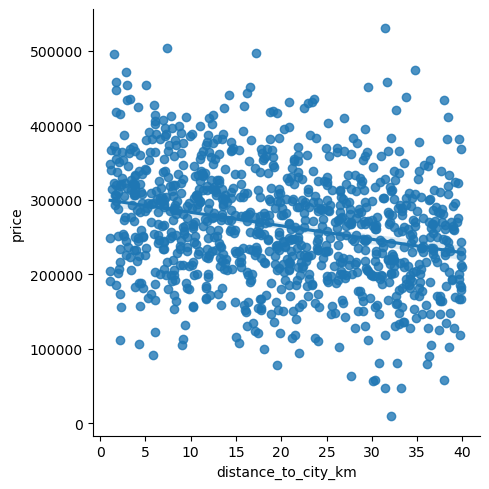

In [11]:
sns.lmplot(data=house_price_prediction, x="distance_to_city_km", y='price')
plt.show()

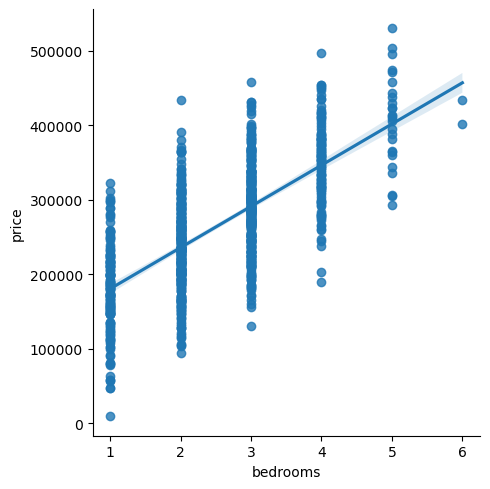

In [12]:
sns.lmplot(data=house_price_prediction, x="bedrooms", y='price')
plt.show()

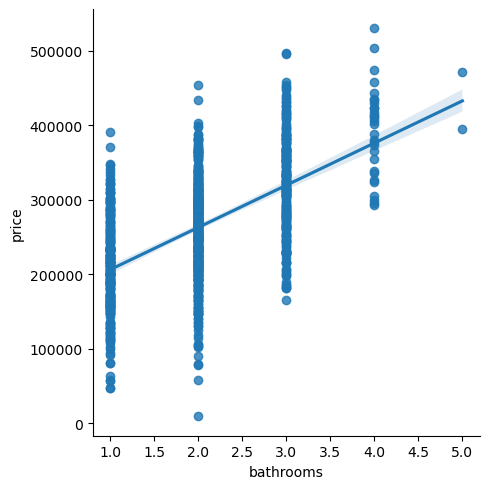

In [13]:
sns.lmplot(data=house_price_prediction, x="bathrooms", y='price')
plt.show()

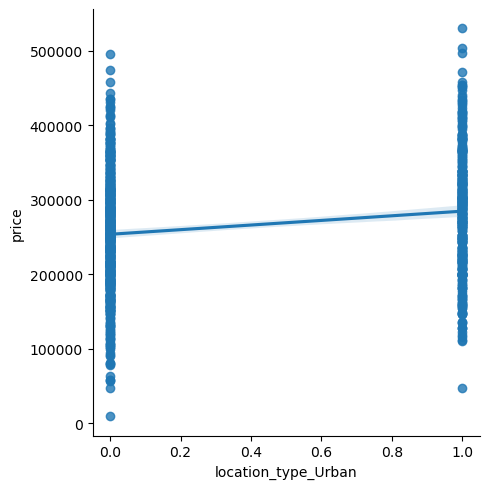

In [14]:
sns.lmplot(data=house_price_prediction, x="location_type_Urban", y='price')
plt.show()

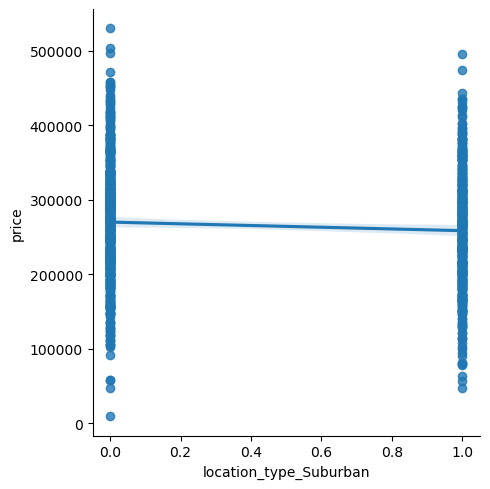

In [15]:
sns.lmplot(data=house_price_prediction, x="location_type_Suburban", y='price')
plt.show()

## Check the Normality test

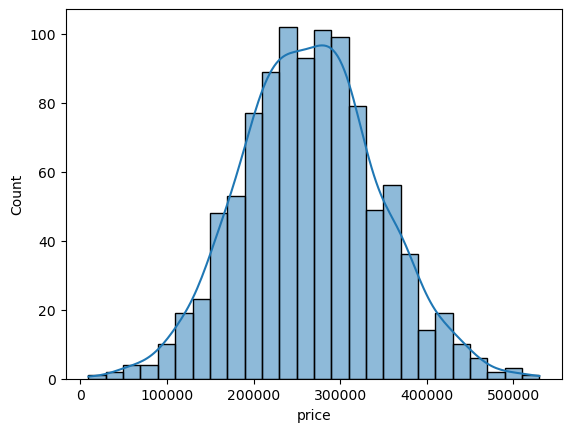

In [16]:
sns.histplot(house_price_prediction["price"], kde=True)
plt.show()

## Correlation Test

In [17]:
house_corr = house_price_prediction.corr()
house_corr

,sqft,bedrooms,bathrooms,house_age_years,distance_to_city_km,garage_spaces,price,location_type_Suburban,location_type_Urban
sqft,1.000000,0.659110,0.490698,0.022138,-0.034491,-0.065577,0.873158,-0.013514,0.021997
bedrooms,0.659110,1.000000,0.701007,-0.006429,-0.060825,-0.060488,0.689471,-0.039815,0.033882
bathrooms,0.490698,0.701007,1.000000,-0.006541,-0.042520,-0.035587,0.566682,-0.009640,0.025996
house_age_years,0.022138,-0.006429,-0.006541,1.000000,0.001530,-0.047569,-0.194246,0.023329,0.024894
distance_to_city_km,-0.034491,-0.060825,-0.042520,0.001530,1.000000,-0.010081,-0.255962,0.034918,-0.015044
garage_spaces,-0.065577,-0.060488,-0.035587,-0.047569,-0.010081,1.000000,0.049028,-0.029812,-0.007481
price,0.873158,0.689471,0.566682,-0.194246,-0.255962,0.049028,1.000000,-0.072659,0.189869
location_type_Suburban,-0.013514,-0.039815,-0.009640,0.023329,0.034918,-0.029812,-0.072659,1.000000,-0.669312
location_type_Urban,0.021997,0.033882,0.025996,0.024894,-0.015044,-0.007481,0.189869,-0.669312,1.000000


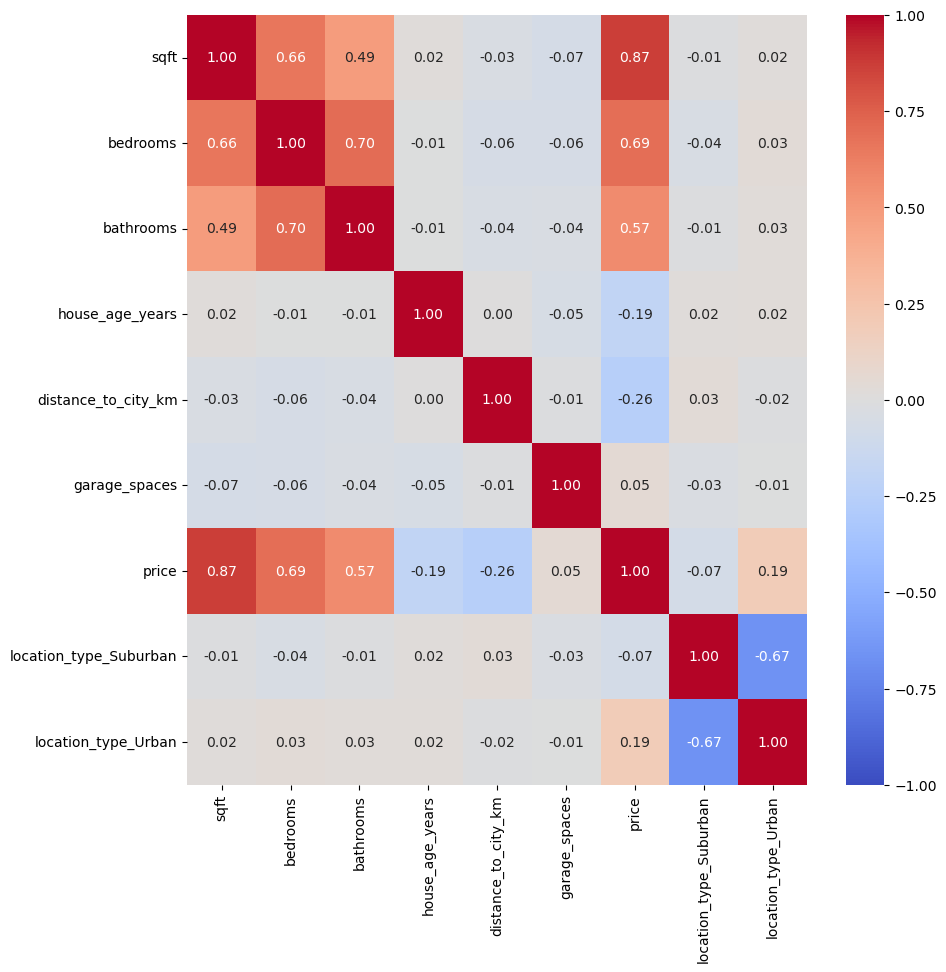

In [18]:
plt.figure(figsize=(10,10))
sns.heatmap(house_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.show()

In [30]:
X=house_price_prediction.drop("price", axis=1)
X

,sqft,bedrooms,bathrooms,house_age_years,distance_to_city_km,garage_spaces,location_type_Suburban,location_type_Urban
0,1952,3,2,32,6.5,0,False,True
1,1280,1,1,58,13.0,2,True,False
2,2175,3,3,4,18.4,2,True,False
3,2270,4,3,49,13.6,0,False,False
4,824,1,1,32,16.1,2,False,True
...,...,...,...,...,...,...,...,...
995,1976,3,2,51,30.4,0,True,False
996,2183,3,2,13,2.4,0,False,True
997,1861,3,3,18,22.6,1,False,True
998,1865,2,2,10,23.5,1,False,True


In [29]:
y=house_price_prediction["price"]
y

0      325500
1      173300
2      368400
3      292100
4      149000
        ...  
995    264500
996    364100
997    292600
998    271600
999    306200
Name: price, Length: 1000, dtype: int64

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=23)

In [20]:
lm=LinearRegression()
lm

LinearRegression()

In [34]:
lm_model = lm.fit(X_train, y_train)
lm_model

LinearRegression()

In [38]:
y_test_pred = lm_model.predict(X_test)

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,root_mean_squared_error,r2_score

In [41]:
mean_absolute_error(y_test, y_test_pred)

16518.692513312857

In [42]:
mean_squared_error(y_test, y_test_pred)

447861744.89065135

In [45]:
root_mean_squared_error(y_test, y_test_pred)

21162.744266532434

In [46]:
r2_score(y_test,y_test_pred)

0.9378147694966817

## Find out the Residual

In [48]:
residuals=y_test - y_test_pred
residuals

519     -303.388853
837   -12252.313584
208   -21192.076429
525     6539.404269
978   -20493.776958
           ...     
647    -2071.679543
481   -12697.744596
134      952.274215
366   -23132.735903
879   -13657.853442
Name: price, Length: 200, dtype: float64

In [52]:
import numpy as np
print ("Train Residual mean ", y_train, lm_model.predict(X_train).mean())
print ("Test Residual mean ", residuals.mean())


Train Residual mean  228    182000
45     230900
373    312100
813    193000
448    313700
        ...  
950    123400
969    244400
40     341400
742    178100
595    319800
Name: price, Length: 800, dtype: int64 265751.74999999994
Test Residual mean  -1122.0248384045074


In [53]:
from scipy import stats
print(stats.ttest_1samp(residuals, 0))   # p > 0.05 means mean is not significantly different from 0

TtestResult(statistic=np.float64(-0.7489766630514518), pvalue=np.float64(0.45475565291961784), df=np.int64(199))


## Homoscadascity Test

In [56]:
from matplotlib import pyplot as plt
import seaborn as sns


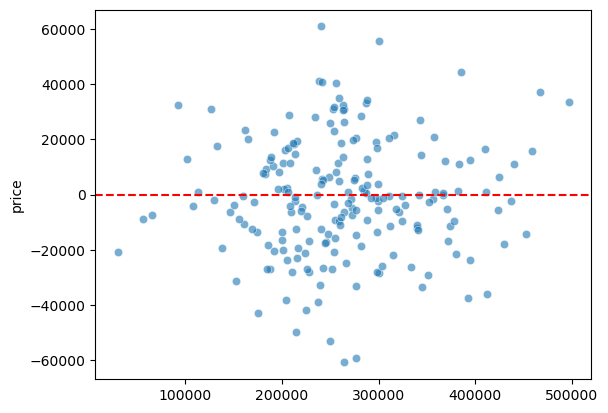

In [63]:
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6)
plt.axhline(0, color='red',linestyle='--')
plt.show()

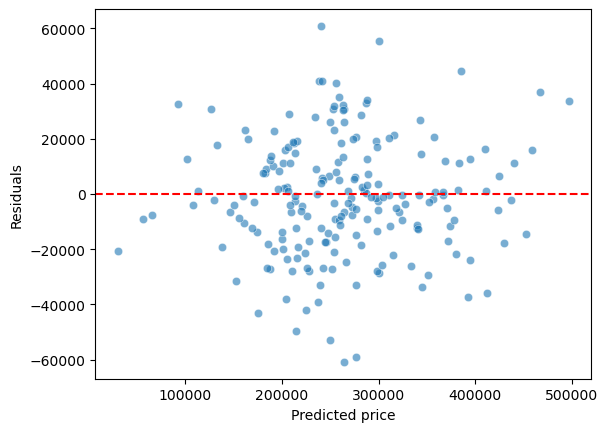

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price")
plt.ylabel("Residuals")
plt.show()